<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Earth Observation Time Series](https://github.com/Query-farm/vgi-earth-observation)

Optical index and calibrated radar histories for geospatial SQL queries.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-earth-observation/blob/main/notebooks/02_latest_radar_row_is_not_latest_measurement.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-earth-observation/blob/main/notebooks/README.md)

## The latest radar row is not always a measurement

How should a dashboard summarize a radar history whose newest acquisition has
no usable pixels? We request **prepared calibrated intensity**, keep viewing
groups and polarizations separate, and distinguish the latest returned row from
the latest usable measurement. A −10 dB change corresponds to one tenth of the
prior mean linear power; a missing return has no such ratio.

The worker ships three **synthetic** acquisitions over two polygon fixtures.
Their satellite/track labels are illustrative metadata. These are not real
Sentinel-1 observations, raw SAR, complex SLC, coherence or damage assessments.
No external imagery or provider account is used.

### Select the inclusive acquisition endpoint

Default `END_DATE` includes the September 3 acquisition with no usable pixels.
The experiment ends on August 22, excluding that acquisition. Predict fewer
returned rows and a usable latest row, while every shared acquisition value
and the August 10→August 22 power change remain fixed. A shorter window does
not improve the underlying observation quality.

In [1]:
END_DATE = "2025-09-03T00:00:00Z"  # Experiment: "2025-08-22T00:00:00Z"

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.29":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.29"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from IPython.display import display
from vgi_notebooks import check_runtime, connect, prepare, prose, theme

check_runtime()
prepare("earth-observation")

import earth_example as example  # noqa: E402 — download before import

example.validate_window(END_DATE)
theme()
session = connect(globals())
con = session.connection

### Connect to the same public release

The released worker resolves `demo://radar-scenes.json` and its TIFF assets
inside its own environment. Python only formats returned tables and figures;
VGI performs raster measurement and SQL constructs temporal comparisons.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'earth_observation' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-earth-observation@v0.1.0 vgi-earth-observation-worker');

,Success


### Retain region IDs and viewing metadata

Both parcels use EPSG:32618 polygon WKB. The worker uses pixel centres and
reports the valid and total pixel counts. These sources are calibrated linear
power, so `value_unit` is explicit. For decibel source rasters the worker would
convert each pixel to power before averaging; changing that option without
changing source units would be incorrect.

We materialize a fixed full-window reference and the selected window. Each
row retains platform, relative orbit, ascending/descending state and
polarization. Identical fixture values across parcels do not justify dropping
these keys from a real temporal comparison.

In [5]:
%%sql
CREATE TABLE regions AS SELECT parcel_id AS region_id,geometry_wkb
FROM earth_observation.main.demo_input;
CREATE TABLE reference AS SELECT * FROM earth_observation.main.radar_series(
 (SELECT * FROM regions),catalog:='demo://radar-scenes.json',geometry_crs:='EPSG:32618',
 start_date:='2025-08-10T00:00:00Z',end_date:='2025-09-03T00:00:00Z',
 polarizations:='vv,vh',value_unit:='linear_power',min_coverage:=0.9,max_scenes:=3,max_pages:=1,max_pixels:=100);
CREATE TABLE history AS SELECT * FROM earth_observation.main.radar_series(
 (SELECT * FROM regions),catalog:='demo://radar-scenes.json',geometry_crs:='EPSG:32618',
 start_date:='2025-08-10T00:00:00Z',end_date:='{{END_DATE}}',
 polarizations:='vv,vh',value_unit:='linear_power',min_coverage:=0.9,max_scenes:=3,max_pages:=1,max_pixels:=100);

,Count


In [6]:
%%sql history <<
SELECT region_id,observed_at,platform,relative_orbit,orbit_state,polarization,
 mean_power,mean_db,valid_pixels,total_pixels,coverage_fraction,status
FROM history ORDER BY region_id,observed_at,polarization;

,region_id,observed_at,platform,relative_orbit,orbit_state,polarization,mean_power,mean_db,valid_pixels,total_pixels,coverage_fraction,status
0,field-a,2025-08-10,sentinel-1a,77,ascending,VH,0.010,-20.0,16,16,1.0,ok
1,field-a,2025-08-10,sentinel-1a,77,ascending,VV,0.100,-10.0,16,16,1.0,ok
2,field-a,2025-08-22,sentinel-1a,77,ascending,VH,0.001,-30.0,16,16,1.0,ok
3,field-a,2025-08-22,sentinel-1a,77,ascending,VV,0.010,-20.0,16,16,1.0,ok
4,field-a,2025-09-03,sentinel-1a,77,ascending,VH,NaN,NaN,0,16,0.0,insufficient_coverage
5,field-a,2025-09-03,sentinel-1a,77,ascending,VV,NaN,NaN,0,16,0.0,insufficient_coverage
6,field-b,2025-08-10,sentinel-1a,77,ascending,VH,0.010,-20.0,8,8,1.0,ok
7,field-b,2025-08-10,sentinel-1a,77,ascending,VV,0.100,-10.0,8,8,1.0,ok
8,field-b,2025-08-22,sentinel-1a,77,ascending,VH,0.001,-30.0,8,8,1.0,ok
9,field-b,2025-08-22,sentinel-1a,77,ascending,VV,0.010,-20.0,8,8,1.0,ok


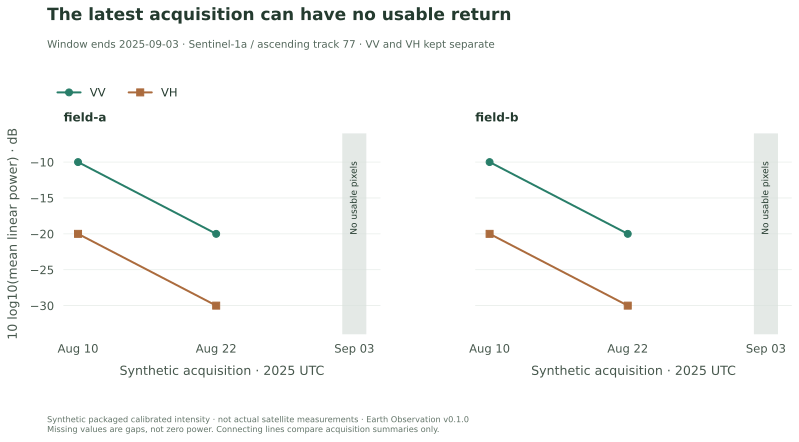

The selected window returns **12 rows**, including **4 without a mean**. A missing mean has zero valid pixels here, while the parcel denominator remains 16 or 8. Neither zero dB (unit linear power) nor zero power is a substitute for those NULL values.

In [7]:
display(history)
example.plot_radar(history, END_DATE)
missing = int(history.mean_power.isna().sum())
prose(
    f"The selected window returns **{len(history)} rows**, including **{missing} without a mean**. "
    "A missing mean has zero valid pixels here, while the parcel denominator remains 16 or 8. "
    "Neither zero dB (unit linear power) nor zero power is a substitute for those NULL values."
)

### Keep the latest row even when its value is NULL

A maximum date and a latest non-null value can refer to different acquisitions.
We rank **all** returned rows to retain the latest status, then independently
rank usable rows for the latest measurement. The dates stay beside their values.
This prevents an old measurement from being presented with a newer acquisition
label. It does not infer any unobserved change during the gap.

In [8]:
%%sql latest <<
CREATE TABLE latest_rows AS
 SELECT * FROM history QUALIFY row_number() OVER(
 PARTITION BY region_id,platform,relative_orbit,orbit_state,polarization ORDER BY observed_at DESC)=1;
CREATE TABLE latest_valid AS
 SELECT * FROM history WHERE status='ok' AND mean_power IS NOT NULL
 QUALIFY row_number() OVER(
 PARTITION BY region_id,platform,relative_orbit,orbit_state,polarization ORDER BY observed_at DESC)=1;
SELECT a.region_id,a.polarization,a.observed_at::DATE AS latest_row_date,a.status AS latest_status,
 a.mean_db AS latest_row_db,v.observed_at::DATE AS latest_measurement_date,v.mean_db AS latest_usable_db
FROM latest_rows a LEFT JOIN latest_valid v USING(region_id,platform,relative_orbit,orbit_state,polarization)
ORDER BY a.region_id,a.polarization;

In [9]:
display(latest)
stale = int((latest.latest_row_date != latest.latest_measurement_date).sum())
prose(
    f"In **{stale} of {len(latest)} viewing groups**, the latest usable value predates the latest returned row. "
    "The two dates are reported separately. Excluding the unavailable September acquisition removes this "
    "date difference from the selected window, but supplies no new measurement."
)

,region_id,polarization,latest_row_date,latest_status,latest_row_db,latest_measurement_date,latest_usable_db
0,field-a,VH,2025-09-03,insufficient_coverage,NaN,2025-08-22,-30.0
1,field-a,VV,2025-09-03,insufficient_coverage,NaN,2025-08-22,-20.0
2,field-b,VH,2025-09-03,insufficient_coverage,NaN,2025-08-22,-30.0
3,field-b,VV,2025-09-03,insufficient_coverage,NaN,2025-08-22,-20.0


In **4 of 4 viewing groups**, the latest usable value predates the latest returned row. The two dates are reported separately. Excluding the unavailable September acquisition removes this date difference from the selected window, but supplies no new measurement.

### Reconcile decibel differences with power ratios

Within each viewing group, compare consecutive **usable** acquisitions. Keep
their dates and gap length. This fixture has a 12-day gap; skipping an unavailable
row is explicit and is not interpolation. A difference in mean dB must equal
`10*log10(current_mean_power / previous_mean_power)`. Neither channel nor track
is pooled, and we do not interpret the change as damage probability.

In [10]:
%%sql changes <<
CREATE TABLE usable_changes AS
 SELECT *,mean_power/previous_power AS power_ratio,
 mean_db-previous_db AS delta_db,
 10*log10(mean_power/previous_power) AS ratio_db,
 date_diff('day',previous_time,observed_at) AS gap_days
 FROM (
  SELECT *,lag(mean_power) OVER w AS previous_power,lag(mean_db) OVER w AS previous_db,
   lag(observed_at) OVER w AS previous_time
  FROM history WHERE status='ok' AND mean_power IS NOT NULL
  WINDOW w AS (PARTITION BY region_id,platform,relative_orbit,orbit_state,polarization ORDER BY observed_at)
 ) WHERE previous_time IS NOT NULL;
SELECT region_id,polarization,previous_time::DATE AS previous_date,observed_at::DATE AS current_date,
 gap_days,power_ratio,delta_db,ratio_db FROM usable_changes ORDER BY region_id,polarization;

In [11]:
display(changes)
prose(
    f"All **{len(changes)} usable comparisons** span {int(changes.gap_days.iloc[0])} days. "
    f"Their mean power ratio is **{changes.power_ratio.mean():.3f}**, with a mean change of "
    f"**{changes.delta_db.mean():.1f}dB**. These identical constructed changes exercise the conversion "
    "and grouping rules; they are not evidence of one real event or independent replications."
)

,region_id,polarization,previous_date,current_date,gap_days,power_ratio,delta_db,ratio_db
0,field-a,VH,2025-08-10,2025-08-22,12,0.1,-10.0,-10.0
1,field-a,VV,2025-08-10,2025-08-22,12,0.1,-10.0,-10.0
2,field-b,VH,2025-08-10,2025-08-22,12,0.1,-10.0,-10.0
3,field-b,VV,2025-08-10,2025-08-22,12,0.1,-10.0,-10.0


All **4 usable comparisons** span 12 days. Their mean power ratio is **0.100**, with a mean change of **-10.0dB**. These identical constructed changes exercise the conversion and grouping rules; they are not evidence of one real event or independent replications.

### Check window selection, NULLs and grouped comparisons

The selected rows must exactly equal the bounded subset of the full reference,
including NULL values and metadata. Counts, coverage and power-to-dB conversion
are reconciled separately. We also verify that the latest-row calculation keeps
all four region/channel groups and that no comparison crosses their identities.

In [12]:
%%sql checks <<
SELECT 'window equals full-reference subset' AS check_name,NOT EXISTS(
 (SELECT * FROM history EXCEPT ALL SELECT * FROM reference WHERE observed_at<=CAST('{{END_DATE}}' AS TIMESTAMP))
 UNION ALL (SELECT * FROM reference WHERE observed_at<=CAST('{{END_DATE}}' AS TIMESTAMP) EXCEPT ALL SELECT * FROM history)) AS passed
UNION ALL SELECT 'unique acquisition keys',count(*)=count(DISTINCT(region_id,observed_at,platform,relative_orbit,orbit_state,polarization)) FROM history
UNION ALL SELECT 'coverage matches counts',bool_and(total_pixels>0 AND valid_pixels BETWEEN 0 AND total_pixels AND abs(coverage_fraction-valid_pixels::DOUBLE/total_pixels)<1e-12) FROM history
UNION ALL SELECT 'mean availability matches status',bool_and((mean_power IS NULL)=(status<>'ok') AND (mean_db IS NULL)=(mean_power IS NULL)) FROM history
UNION ALL SELECT 'reported dB matches power',bool_and(mean_power>0 AND abs(mean_db-10*log10(mean_power))<1e-10) FROM history WHERE mean_power IS NOT NULL
UNION ALL SELECT 'four groups retain latest rows',count(*)=4 AND count(DISTINCT(region_id,polarization))=4 FROM latest_rows
UNION ALL SELECT 'usable endpoint dates retained',bool_and(observed_at=TIMESTAMP '2025-08-22') FROM latest_valid
UNION ALL SELECT 'four same-track 12-day comparisons',count(*)=4 AND bool_and(gap_days=12 AND platform='sentinel-1a' AND relative_orbit=77 AND orbit_state='ascending') FROM usable_changes
UNION ALL SELECT 'power-ratio logarithm agrees',bool_and(abs(delta_db-ratio_db)<1e-10 AND abs(power_ratio-0.1)<1e-6) FROM usable_changes
UNION ALL SELECT 'fixed complete reference retains missing rows',count(*)=12 AND count(mean_power)=8 FROM reference
ORDER BY check_name;

In [13]:
display(checks)
assert len(checks) == 10 and checks.passed.notna().all() and checks.passed.all()
assert len(history) in (8, 12) and len(changes) == 4
prose(
    "All ten checks pass. The optical fixtures in notebook 01 are dated 2026 and these radar fixtures 2025; "
    "their shared parcel IDs permit a join but do not align an event. Real applications must also justify "
    "calibration, viewing geometry, temporal alignment and independence of acquisitions."
)

,check_name,passed
0,coverage matches counts,True
1,fixed complete reference retains missing rows,True
2,four groups retain latest rows,True
3,four same-track 12-day comparisons,True
4,mean availability matches status,True
5,power-ratio logarithm agrees,True
6,reported dB matches power,True
7,unique acquisition keys,True
8,usable endpoint dates retained,True
9,window equals full-reference subset,True


All ten checks pass. The optical fixtures in notebook 01 are dated 2026 and these radar fixtures 2025; their shared parcel IDs permit a join but do not align an event. Real applications must also justify calibration, viewing geometry, temporal alignment and independence of acquisitions.

### Experiment: stop before the unavailable acquisition

Set `END_DATE` to **2025-08-22T00:00:00Z**, restart and run all. Predict **8 rather
than 12 rows**, no unavailable rows in this window, and the latest row date equal
to the latest usable date. The four August 10→August 22 comparisons must stay
identical, as must every shared row's measurements, counts and viewing metadata.
The full reference still contains the four unavailable September 3 rows. Reset
the endpoint to **2025-09-03T00:00:00Z** to reproduce the published example.

In [14]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-earth-observation](https://github.com/Query-farm/vgi-earth-observation)